# 01. EDA — 유해남조류(녹조) 7일 예측

**목적**: 결합된 데이터(`data/processed/bloom.parquet`)의 구조·결측·계절성·지점 특성을 파악하고,
단순 베이스라인(persistence, climatology)의 공식 지표를 산출해 모델이 넘어야 할 기준선을 정한다.

**공식 과제 정의 요약** (2026-10-15 개정)
- 기준일(실제 측정일)로부터 **+7일에 가장 가까운 측정(±3일)** 의 세포수 `iem_bgalage_cell_co` 를 회귀 예측
- 지점 5곳: 해평, 강정·고령, 칠서, 물금·매리(낙동강), 대청호 회남(금강)
- 분할: ~2024 학습 / 2025 검증 / 2026 평가. **기준일 이후 관측 사용 금지**
- 지표: log10(세포수+1) RMSE·MAE, 원 단위 R²·NSE(목표 R² 0.6, NSE 0.5), 보조 F1(10,000 cells/mL 초과)

**실행 전 준비**
```bash
make sample && make data-sample   # 샘플 데이터로 점검할 때
make data                         # 실제 배포 데이터를 data/raw, data/external 에 넣은 뒤
```


In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from data_ai import viz
from data_ai.bloom import ALERT_THRESHOLDS
from data_ai.config import FIGURES_DIR, PROCESSED_DIR
from data_ai.evaluate import bloom_metrics

warnings.filterwarnings("ignore")
viz.apply_style()
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", 60, "display.width", 160, "display.float_format", "{:,.2f}".format)

df = pd.read_parquet(PROCESSED_DIR / "bloom.parquet")
df["date"] = pd.to_datetime(df["date"])
SITES = list(df.groupby("site_code")["site_name"].first().items())   # 고정 순서 → 색상 고정
SITE_COLOR = {code: viz.SERIES[i] for i, (code, _) in enumerate(SITES)}
print(df.shape, "|", df["date"].min().date(), "~", df["date"].max().date())

(1754, 93) | 2018-01-08 ~ 2026-08-31


## 1. 데이터 개요
지점별 행 수, 기간, 측정 간격, 정답 유효 비율, 분할 구성.

In [2]:
overview = (
    df.groupby(["site_code", "site_name"])
    .agg(
        n=("date", "size"),
        start=("date", "min"),
        end=("date", "max"),
        median_gap_days=("days_since_prev", "median"),
        target_valid_rate=("target_valid", "mean"),
        cells_median=("cyano_cells", "median"),
        cells_max=("cyano_cells", "max"),
    )
    .reset_index()
)
display(overview)
display(pd.crosstab(df["site_name"], df["split"], margins=True))

,site_code,site_name,n,start,end,median_gap_days,target_valid_rate,cells_median,cells_max
0,2011G26,해평,346,2018-09-24,2026-08-31,7.00,0.80,"1,225.00","1,995,262.00"
1,2011G56,강정·고령,340,2019-01-07,2026-08-31,7.00,0.80,525.00,"1,995,262.00"
2,2020G33,칠서,332,2018-12-10,2026-08-31,7.00,0.79,916.00,"1,995,262.00"
3,2022G05,물금·매리,362,2018-05-21,2026-08-31,7.00,0.81,"2,555.00","1,995,262.00"
4,3008G30,대청호 회남,374,2018-01-08,2026-08-31,7.00,0.78,576.00,"1,995,262.00"


split,test,train,valid,All
site_name,,,,
강정·고령,29,267,44,340
대청호 회남,29,300,45,374
물금·매리,30,288,44,362
칠서,31,259,42,332
해평,31,273,42,346
All,150,1387,217,1754


## 2. 결측 현황
유량 증가 시 미채수 등으로 결측이 생긴다(공식 설명). 결측 대체 전략은 평가 항목이므로 어디에 얼마나 비어 있는지 먼저 본다.

,결측 %
target_cells,20.40
cyano_cells,1.90
water_temp,0.00
transparency,0.00
turbidity,0.00
do,0.00
ph,0.00
chl_a,0.00
w_temp_mean,0.00
w_solar_mean7d,0.00


findfont: Failed to find font weight normal for WenQuanYi Zen Hei, now using 500.


findfont: Failed to find font weight semibold for WenQuanYi Zen Hei, now using 500.


findfont: Failed to find font weight normal for WenQuanYi Zen Hei, now using 500.


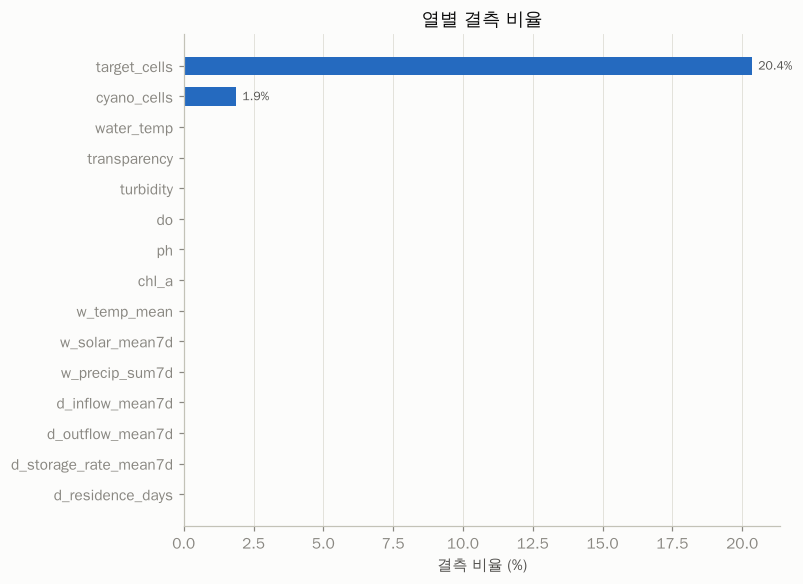

In [3]:
key_cols = [c for c in ["cyano_cells", "water_temp", "ph", "transparency", "turbidity", "do", "chl_a",
                        "w_temp_mean", "w_precip_sum7d", "w_solar_mean7d", "d_inflow_mean7d", "d_outflow_mean7d",
                        "d_storage_rate_mean7d", "d_residence_days", "target_cells"] if c in df.columns]
missing = (df[key_cols].isna().mean() * 100).sort_values(ascending=False)
display(missing.round(1).to_frame("결측 %"))

fig, ax = plt.subplots(figsize=(7, 0.32 * len(missing) + 1))
ax.barh(missing.index[::-1], missing.values[::-1], color=viz.SEQUENTIAL[4], height=0.6)
for y, v in enumerate(missing.values[::-1]):
    if v > 0:
        ax.annotate(f"{v:.1f}%", (v, y), xytext=(4, 0), textcoords="offset points", va="center", fontsize=8, color=viz.INK_SECONDARY)
ax.set_xlabel("결측 비율 (%)"); ax.set_title("열별 결측 비율"); ax.grid(axis="y", visible=False)
fig.savefig(FIGURES_DIR / "eda_missing.png"); plt.show()

## 3. 측정 간격과 정답 간격
주 1회가 기본이지만 겨울철·결측으로 간격이 벌어진다. 정답은 +7일 ±3일 안의 측정만 인정되므로 간격 분포가 곧 채점 대상 비율을 결정한다.

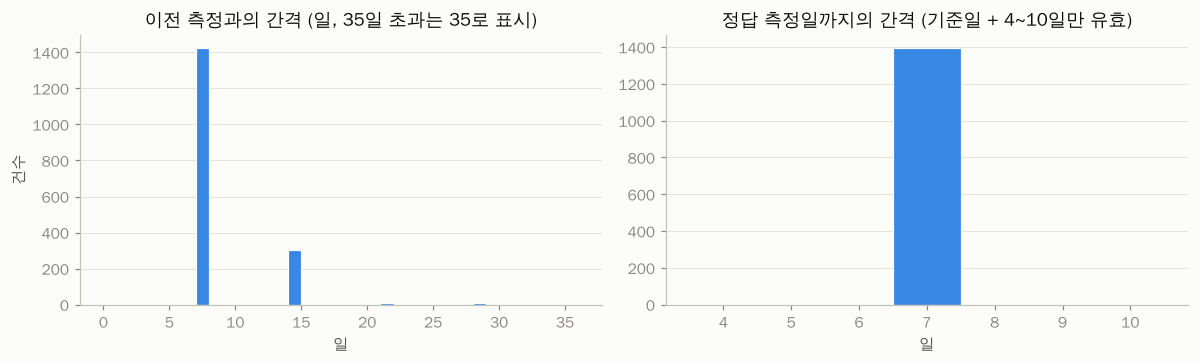

정답 유효 비율: 79.6% | 정확히 7일: 100.0%


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
gap = df["days_since_prev"].dropna().clip(upper=35)
axes[0].hist(gap, bins=np.arange(0, 37, 1), color=viz.SEQUENTIAL[3], edgecolor=viz.SURFACE, linewidth=0.8)
axes[0].set_title("이전 측정과의 간격 (일, 35일 초과는 35로 표시)"); axes[0].set_xlabel("일"); axes[0].set_ylabel("건수")
tg = df.loc[df["target_valid"], "target_gap_days"]
axes[1].hist(tg, bins=np.arange(3.5, 11.5, 1), color=viz.SEQUENTIAL[3], edgecolor=viz.SURFACE, linewidth=0.8)
axes[1].set_title("정답 측정일까지의 간격 (기준일 + 4~10일만 유효)"); axes[1].set_xlabel("일")
for ax in axes: ax.grid(axis="x", visible=False)
fig.tight_layout(); fig.savefig(FIGURES_DIR / "eda_gaps.png"); plt.show()
print("정답 유효 비율:", f"{df['target_valid'].mean():.1%}", "| 정확히 7일:", f"{(tg == 7).mean():.1%}")

## 4. 지점별 세포수 시계열
로그 축. 점선은 조류경보제 기준(관심 1,000 / 경계 10,000 / 대발생 1,000,000 cells/mL). 음영은 검증(2025)·평가(2026) 구간.

findfont: Failed to find font weight normal for WenQuanYi Zen Hei, now using 500.


findfont: Failed to find font weight semibold for WenQuanYi Zen Hei, now using 500.


findfont: Failed to find font weight normal for WenQuanYi Zen Hei, now using 500.


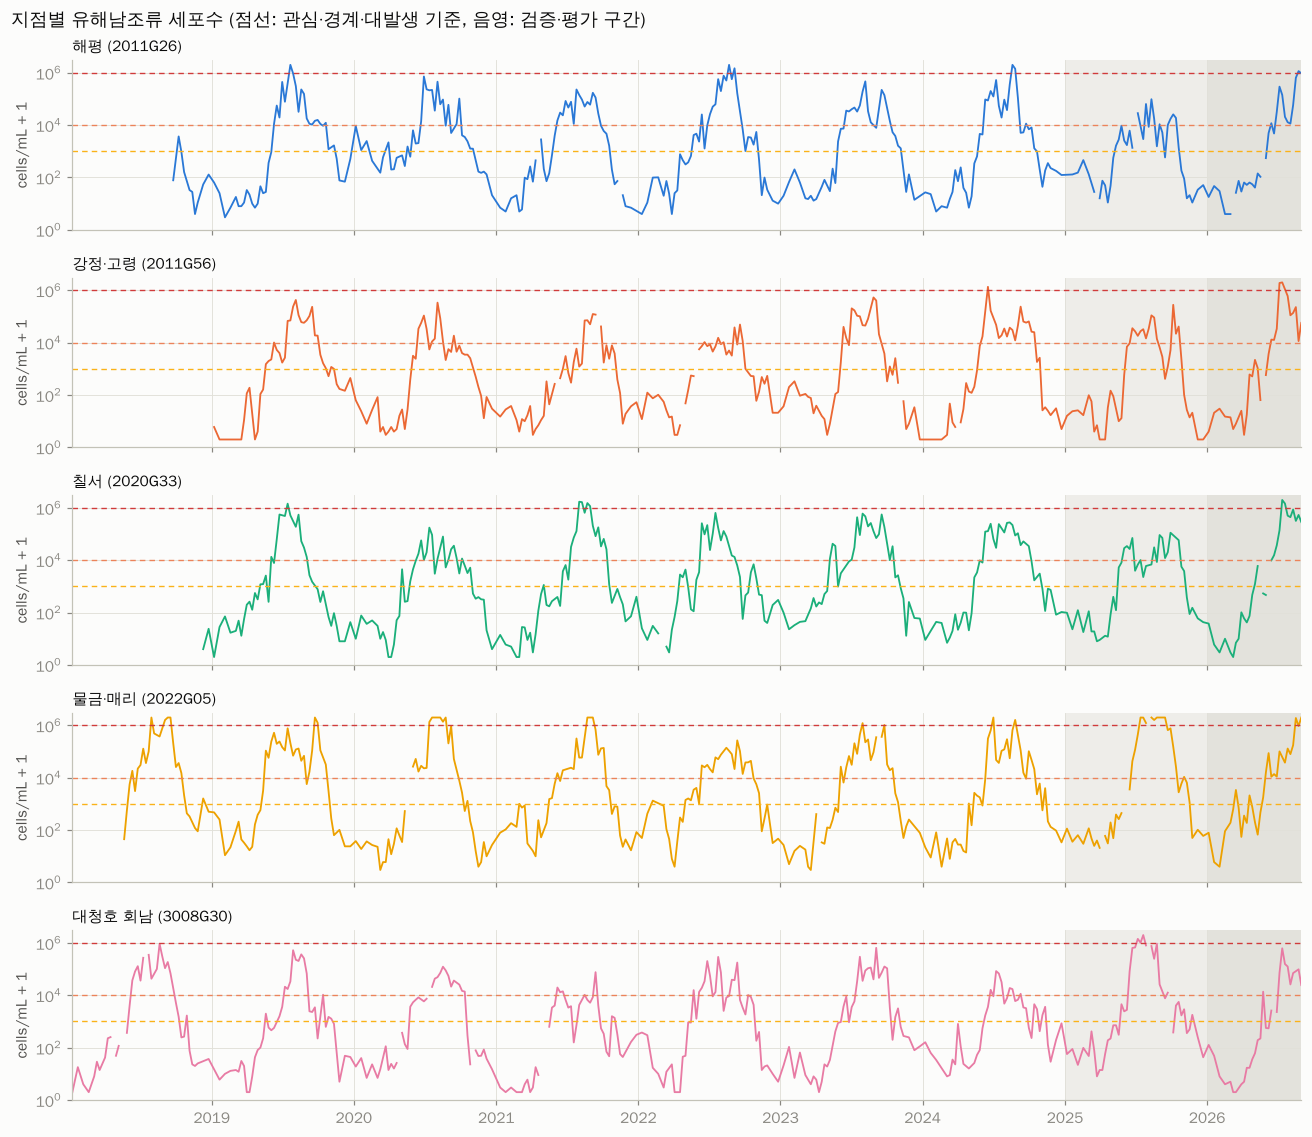

In [5]:
fig, axes = plt.subplots(len(SITES), 1, figsize=(12, 2.1 * len(SITES)), sharex=True)
for ax, (code, name) in zip(axes, SITES):
    g = df[df["site_code"] == code]
    ax.plot(g["date"], g["cyano_cells"] + 1, color=SITE_COLOR[code], linewidth=1.2)
    ax.set_yscale("log"); ax.set_ylim(1, 3e6)
    for lv, (nm, v) in enumerate(ALERT_THRESHOLDS.items(), start=1):
        ax.axhline(v, color=viz.ALERT_COLORS[lv], linestyle=(0, (4, 3)), linewidth=0.9)
    for yr, lab in [(2025, "검증"), (2026, "평가")]:
        ax.axvspan(pd.Timestamp(f"{yr}-01-01"), pd.Timestamp(f"{yr}-12-31"), color=viz.GRID, alpha=0.5 if yr == 2025 else 0.9, lw=0)
    ax.set_title(f"{name} ({code})", loc="left", fontsize=10); ax.set_ylabel("cells/mL + 1")
axes[-1].set_xlim(df["date"].min(), df["date"].max())
fig.suptitle("지점별 유해남조류 세포수 (점선: 관심·경계·대발생 기준, 음영: 검증·평가 구간)", x=0.01, ha="left")
fig.tight_layout(); fig.savefig(FIGURES_DIR / "eda_timeseries.png"); plt.show()

## 5. 계절성
월별 log10 세포수 중앙값. 폭염 장기화로 발생 시기가 앞당겨지는지(공식 배경: 첫 경보 약 2개월 조기화) 연도별로도 본다.

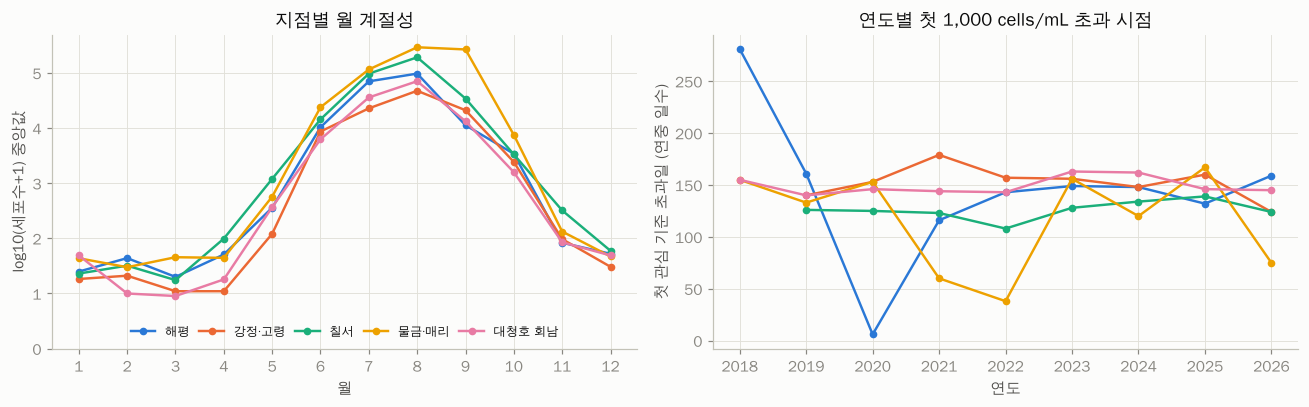

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
m = df.groupby(["site_code", "month"])["log10_cells"].median().unstack(0)
for code, name in SITES:
    axes[0].plot(m.index, m[code], marker="o", markersize=4, color=SITE_COLOR[code], label=name)
axes[0].set_xticks(range(1, 13)); axes[0].set_xlabel("월"); axes[0].set_ylabel("log10(세포수+1) 중앙값")
axes[0].set_ylim(bottom=max(0, m.min().min() - 1.0))   # 범례 자리 확보
axes[0].set_title("지점별 월 계절성"); axes[0].legend(ncol=5, fontsize=8, loc="lower center", columnspacing=0.8)

# 연도별 첫 '관심' 초과일 (조기화 확인)
first = (df[df["cyano_cells"] >= ALERT_THRESHOLDS["관심"]].groupby(["site_code", "year"])["date"].min().dt.dayofyear.unstack(0))
for code, name in SITES:
    if code in first:
        axes[1].plot(first.index, first[code], marker="o", markersize=4, color=SITE_COLOR[code], label=name)
axes[1].set_xlabel("연도"); axes[1].set_ylabel("첫 관심 기준 초과일 (연중 일수)"); axes[1].set_title("연도별 첫 1,000 cells/mL 초과 시점")
fig.tight_layout(); fig.savefig(FIGURES_DIR / "eda_season.png"); plt.show()

## 6. 연도·지점별 경보 단계 비율
경계(10,000) 이상 비율이 보조지표 F1의 양성 비율이 된다. 양성이 드물면 F1이 불안정하므로 미리 확인한다.

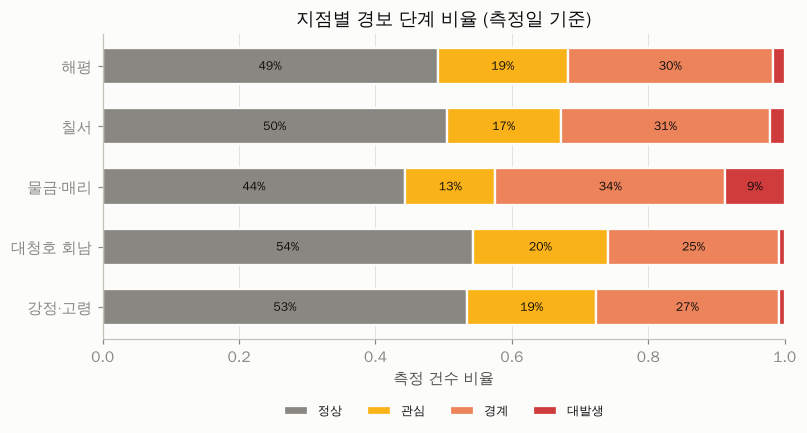

경계(10,000) 이상 비율 — 전체: 31.5% | 검증(2025): 30.0%


In [7]:
lvl = (df.dropna(subset=["current_level"]).assign(level=lambda d: d["current_level"].astype(int))
         .groupby(["site_name", "level"]).size().unstack(fill_value=0))
share = lvl.div(lvl.sum(axis=1), axis=0)
fig, ax = plt.subplots(figsize=(8, 3.6))
left = np.zeros(len(share))
for lv in share.columns:
    vals = share[lv].values
    ax.barh(share.index, vals, left=left, color=viz.ALERT_COLORS[lv], label=viz.ALERT_NAMES[lv], height=0.6,
            edgecolor=viz.SURFACE, linewidth=1.5)
    for y, (l0, v) in enumerate(zip(left, vals)):
        if v >= 0.06:
            ax.text(l0 + v / 2, y, f"{v:.0%}", ha="center", va="center", fontsize=8, color=viz.INK)
    left += vals
ax.set_xlim(0, 1); ax.set_xlabel("측정 건수 비율"); ax.set_title("지점별 경보 단계 비율 (측정일 기준)")
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.18), fontsize=8); ax.grid(axis="y", visible=False)
fig.savefig(FIGURES_DIR / "eda_alert_share.png"); plt.show()
print("경계(10,000) 이상 비율 — 전체:", f"{(df['cyano_cells'] >= 10_000).mean():.1%}",
      "| 검증(2025):", f"{(df.loc[df['split']=='valid','cyano_cells'] >= 10_000).mean():.1%}")

## 7. 어떤 변수가 7일 뒤 세포수와 관련 있나
선행연구(송찬영 외, 2023)는 세포수(로그)와 수온 0.63, 월 0.37, 댐 유입량 0.19, 총방류량 0.19의 상관을 보고했다. 같은 방식으로 **학습 구간(~2024)** 에서 상관을 확인한다.

,Pearson r (vs log10 정답)
log10_cells,0.91
w_temp_mean_mean28d,0.87
chl_a,0.87
w_temp_mean_mean14d,0.87
w_temp_min_min28d,0.86
water_temp,0.86
w_solar_mean28d,0.86
w_temp_max_max28d,0.86
w_temp_max_max14d,0.86
w_temp_mean_mean7d,0.85


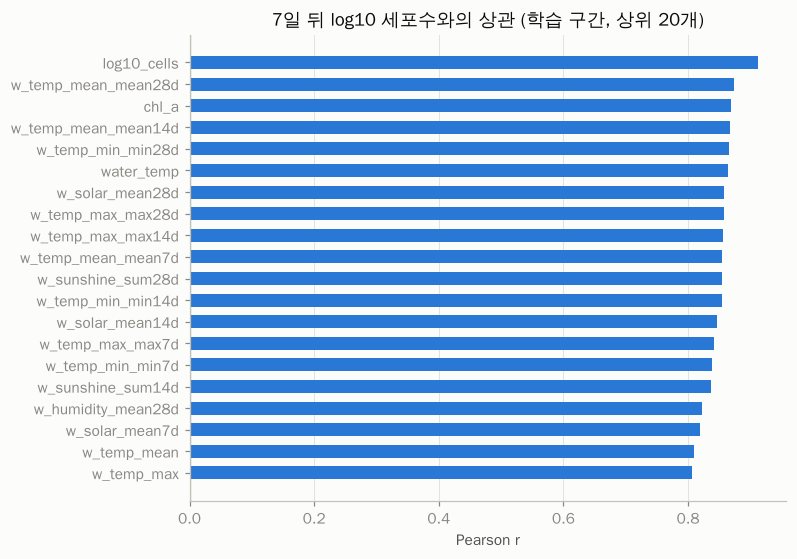

In [8]:
train = df[(df["split"] == "train") & df["target_valid"]]
cands = [c for c in df.columns if c.startswith(("w_", "d_")) or c in
         ["log10_cells", "prev_cells", "water_temp", "ph", "transparency", "turbidity", "do", "chl_a", "month", "doy"]]
corr = train[cands + ["log10_target_cells"]].corr(numeric_only=True)["log10_target_cells"].drop("log10_target_cells")
top = corr.reindex(corr.abs().sort_values(ascending=False).index).head(20)
display(top.round(3).to_frame("Pearson r (vs log10 정답)"))

fig, ax = plt.subplots(figsize=(7, 5.5))
colors = ["#2a78d6" if v >= 0 else "#e34948" for v in top.values[::-1]]   # 양(+) 파랑 / 음(−) 빨강
ax.barh(top.index[::-1], top.values[::-1], color=colors, height=0.6)
ax.axvline(0, color=viz.MUTED, linewidth=0.8); ax.set_xlabel("Pearson r"); ax.set_title("7일 뒤 log10 세포수와의 상관 (학습 구간, 상위 20개)")
ax.grid(axis="y", visible=False); fig.savefig(FIGURES_DIR / "eda_corr.png"); plt.show()

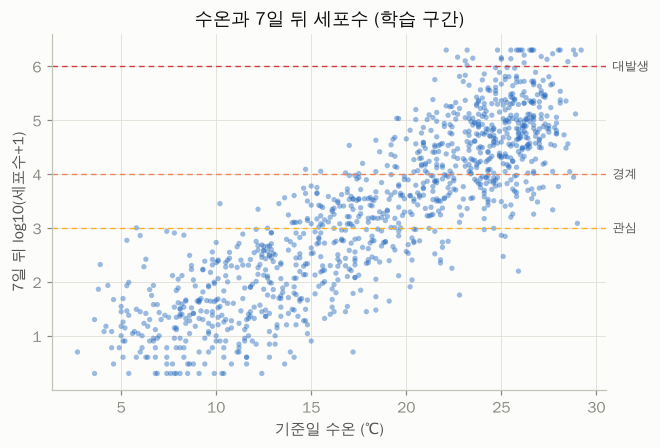

In [9]:
fig, ax = plt.subplots(figsize=(6.5, 4.2))
ax.scatter(train["water_temp"], train["log10_target_cells"], s=12, alpha=0.45, color=viz.SEQUENTIAL[4], edgecolor="none")
ax.set_xlabel("기준일 수온 (℃)"); ax.set_ylabel("7일 뒤 log10(세포수+1)")
ax.set_title("수온과 7일 뒤 세포수 (학습 구간)")
for lv, (nm, v) in enumerate(ALERT_THRESHOLDS.items(), start=1):
    ax.axhline(np.log10(v + 1), color=viz.ALERT_COLORS[lv], linestyle=(0, (4, 3)), linewidth=0.9)
    ax.annotate(nm, xy=(1.0, np.log10(v + 1)), xycoords=("axes fraction", "data"), xytext=(4, 0),
                textcoords="offset points", va="center", fontsize=8, color=viz.INK_SECONDARY)
fig.savefig(FIGURES_DIR / "eda_temp_scatter.png"); plt.show()

## 8. 베이스라인 — 모델이 넘어야 할 선
- **Persistence**: 7일 뒤 = 기준일 세포수
- **Climatology**: 7일 뒤 = 학습 구간의 (지점, 월) 중앙값
- **Blend**: 로그 공간에서 두 값의 평균

검증(2025) 구간에서 공식 지표로 계산한다. 목표는 R² 0.6, NSE 0.5.

In [10]:
valid = df[(df["split"] == "valid") & df["target_valid"]].copy()
clim = train.groupby(["site_code", "month"])["log10_target_cells"].median().rename("clim_log10")
valid = valid.join(clim, on=["site_code", "month"])
valid["pred_persist"] = valid["cyano_cells"]
valid["pred_clim"] = 10 ** valid["clim_log10"] - 1
valid["pred_blend"] = 10 ** ((valid["log10_cells"] + valid["clim_log10"]) / 2) - 1

rows = {name: bloom_metrics(valid["target_cells"], valid[col]) for name, col in
        [("persistence", "pred_persist"), ("climatology", "pred_clim"), ("blend", "pred_blend")]}
baseline = pd.DataFrame(rows).T
display(baseline.round(3))
baseline.to_csv(FIGURES_DIR.parent / "baseline_valid_2025.csv")

,n,rmse_log10,mae_log10,r2,nse,f1_over_threshold
persistence,163.00,0.66,0.52,0.69,0.69,0.78
climatology,170.00,0.85,0.70,0.03,0.03,0.76
blend,163.00,0.61,0.51,0.33,0.33,0.83


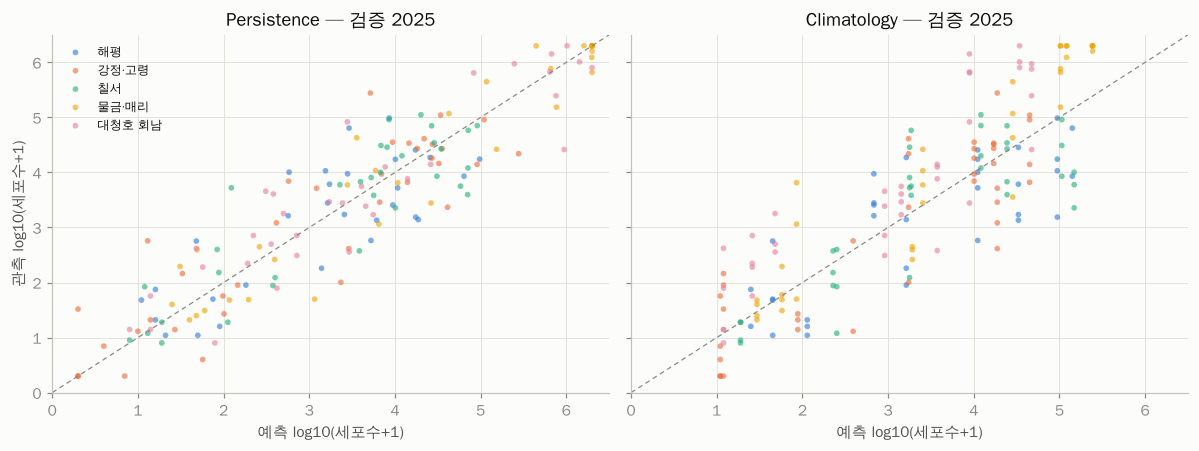

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharex=True, sharey=True)
for ax, (name, col) in zip(axes, [("Persistence", "pred_persist"), ("Climatology", "pred_clim")]):
    for code, sname in SITES:
        g = valid[valid["site_code"] == code]
        ax.scatter(np.log10(g[col] + 1), g["log10_target_cells"], s=14, alpha=0.6, color=SITE_COLOR[code], label=sname, edgecolor="none")
    lim = (0, 6.5)
    ax.plot(lim, lim, color=viz.MUTED, linewidth=0.8, linestyle=(0, (4, 3)))
    ax.set_xlim(lim); ax.set_ylim(lim); ax.set_title(f"{name} — 검증 2025"); ax.set_xlabel("예측 log10(세포수+1)")
axes[0].set_ylabel("관측 log10(세포수+1)"); axes[0].legend(fontsize=8, loc="upper left")
fig.tight_layout(); fig.savefig(FIGURES_DIR / "eda_baseline_scatter.png"); plt.show()

## 9. 급증 사례
공식 배경: 강정·고령 2026-08-13 49,400 → 08-18 483,021 cells/mL (5일 만에 약 10배). 이런 급증을 7일 전에 맞히는 것이 가장 어렵고 가장 중요하다. 학습 데이터에서 유사 사례를 찾아 둔다.

In [12]:
surge = df.dropna(subset=["prev_cells"]).copy()
surge["ratio"] = (surge["cyano_cells"] + 1) / (surge["prev_cells"] + 1)
cols = ["site_name", "date", "days_since_prev", "prev_cells", "cyano_cells", "ratio", "water_temp", "w_precip_sum7d", "d_outflow_mean7d"]
display(surge.sort_values("ratio", ascending=False)[[c for c in cols if c in surge.columns]].head(10))

,site_name,date,days_since_prev,prev_cells,cyano_cells,ratio,water_temp,w_precip_sum7d,d_outflow_mean7d
1226,물금·매리,2023-04-03,14.00,2.00,407.00,136.00,12.10,18.40,1.84
1274,물금·매리,2024-04-29,7.00,13.00,"1,038.00",74.21,15.50,5.50,1.86
837,칠서,2022-06-13,7.00,"3,495.00","257,412.00",73.63,25.20,16.70,21.11
1740,대청호 회남,2026-05-25,7.00,224.00,"13,674.00",60.78,18.40,11.40,36.53
742,칠서,2020-05-04,7.00,73.00,"4,481.00",60.57,18.00,12.50,19.66
1111,물금·매리,2020-07-13,7.00,"23,679.00","1,344,907.00",56.80,26.00,120.10,1.83
678,강정·고령,2026-07-06,7.00,"33,983.00","1,895,539.00",55.78,27.60,96.80,32.84
1235,물금·매리,2023-06-05,7.00,489.00,"26,428.00",53.94,23.90,184.50,1.96
647,강정·고령,2025-10-06,7.00,"5,160.00","277,310.00",53.73,18.70,106.80,33.36
705,칠서,2019-06-03,7.00,256.00,"13,420.00",52.22,20.10,75.80,19.76


## 10. 정리와 다음 단계

**확인할 것 (실제 데이터로 교체 후 다시 실행)**
- 지점별 결측 비율과 측정 간격 → 결측 대체 전략(앞값 채우기, 지점·월 중앙값, 결측 플래그) 결정
- 경계(10,000) 이상 비율 → 보조지표 F1의 안정성
- 베이스라인 지표 → 모델이 최소한 이 값을 넘어야 함

**피처 설계 방향 (공식 '융합 난제' 대응)**
- 누적 강우(7·14·28일), 체류시간 대리변수(저수량/방류량), 이동평균 수온·기온 → 이미 `make_dataset`에서 생성
- 세포수 lag(이전 1~3회 측정), 측정 간격, 지점·월 one-hot 또는 지점별 climatology 편차
- 기준일 이후 정보는 절대 사용하지 않음 (평가 시 실격 사유)

**모델링**: LightGBM(log10 목표) → 연도별 롤링 검증 → quantile 예측 구간 → 국립환경과학원 '녹조 정밀 예측정보'와 비교
